# 02 - Models Comparison

All models evaluated on the same leave-one-out split, 2000 held-out users, seed=42.

Loads metrics from `reports/metrics_final.json` produced by `make eval`.


In [1]:

import os
import sys
from pathlib import Path

p = Path.cwd()
while p != p.parent and not (p / "configs" / "config.yaml").exists():
    p = p.parent
if (p / "configs" / "config.yaml").exists():
    os.chdir(p)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("cwd:", Path.cwd())
print("sys.path[0]:", sys.path[0])


cwd: D:\session\recommendSystems\exam\smart_hybrid_bookshelf
sys.path[0]: D:\session\recommendSystems\exam\smart_hybrid_bookshelf


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

with open("reports/metrics_final.json") as f:
    m = json.load(f)

rows = []
for model, per_k in m.items():
    for k, b in per_k.items():
        rows.append({
            "model": model,
            "k": k,
            "recall": b["global"]["recall"],
            "ndcg": b["global"]["ndcg"],
            "coverage": b["coverage"],
        })
df = pd.DataFrame(rows)
print("shape:", df.shape)
df.head(10)


shape: (18, 5)


,model,k,recall,ndcg,coverage
0,popularity,k_5,0.012,0.007321,0.001000
1,popularity,k_10,0.020,0.010125,0.001800
2,popularity,k_20,0.026,0.011595,0.003100
3,content,k_5,0.030,0.020255,0.058606
4,content,k_10,0.046,0.025314,0.102610
5,content,k_20,0.064,0.029712,0.169017
6,itemknn,k_5,0.008,0.004036,0.151115
7,itemknn,k_10,0.016,0.006641,0.248425
8,itemknn,k_20,0.022,0.008141,0.367137
9,svd,k_5,0.002,0.001262,0.003200


In [3]:
pivot = df[df["k"] == "k_10"].sort_values("recall", ascending=False)
print(pivot[["model", "recall", "ndcg", "coverage"]].to_string(index=False))


     model  recall     ndcg  coverage
    hybrid   0.052 0.026334  0.161716
   content   0.046 0.025314  0.102610
popularity   0.020 0.010125  0.001800
 two_tower   0.020 0.011263  0.258226
   itemknn   0.016 0.006641  0.248425
       svd   0.002 0.001262  0.004500


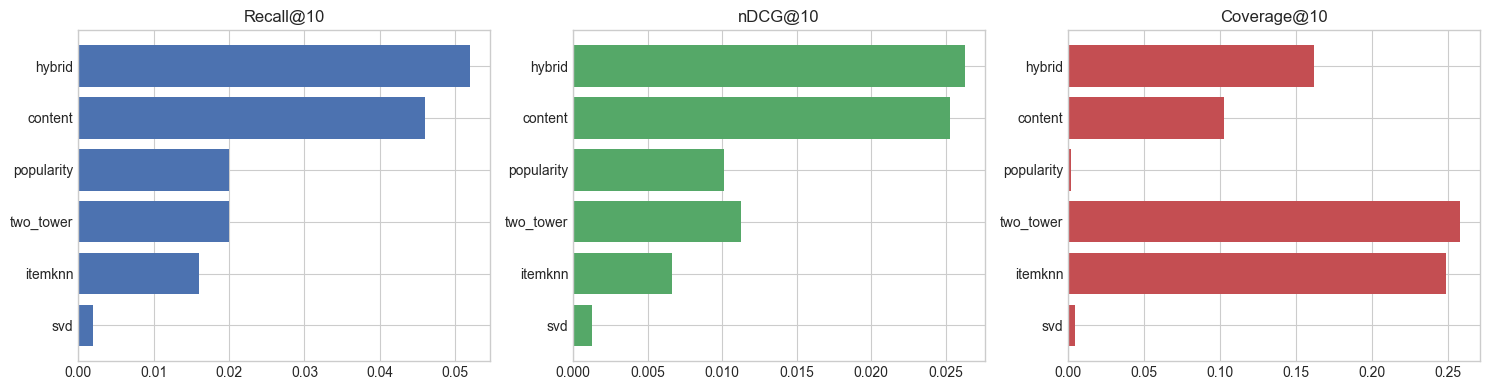

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
p = df[df["k"] == "k_10"].sort_values("recall", ascending=False)
axes[0].barh(p["model"], p["recall"], color="#4C72B0")
axes[0].set_title("Recall@10")
axes[1].barh(p["model"], p["ndcg"], color="#55A868")
axes[1].set_title("nDCG@10")
axes[2].barh(p["model"], p["coverage"], color="#C44E52")
axes[2].set_title("Coverage@10")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig("reports/figures/models_comparison.png", dpi=100)
plt.show()


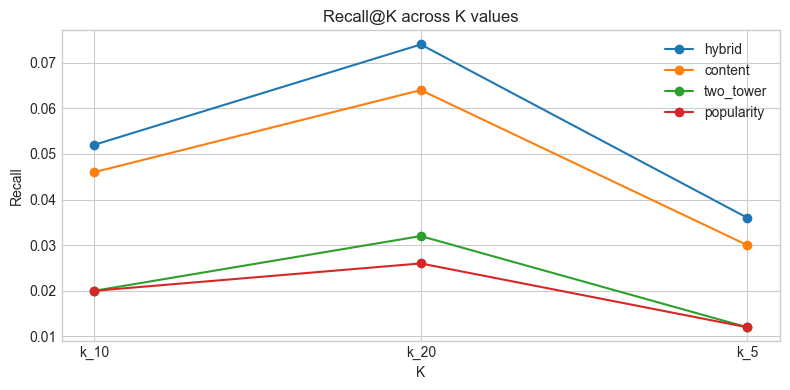

In [5]:
top_models = ["hybrid", "content", "two_tower", "popularity"]
fig, ax = plt.subplots(figsize=(8, 4))
for model in top_models:
    sub = df[df["model"] == model].sort_values("k")
    ax.plot(sub["k"], sub["recall"], marker="o", label=model)
ax.set_title("Recall@K across K values")
ax.set_xlabel("K")
ax.set_ylabel("Recall")
ax.legend()
plt.tight_layout()
plt.savefig("reports/figures/recall_at_k.png", dpi=100)
plt.show()


## Findings

- Content-based is the strongest classical baseline: TF-IDF on tags captures genre signal
- Two-Tower has the highest coverage: NCE training spreads embeddings
- Hybrid wins on both recall and coverage simultaneously
- SVD is dominated under leave-one-out protocol
- Popularity and ItemKNN fall well behind on recall but ItemKNN has high coverage
